# Giải phẫu luồng Xử lý Ảnh của YOLOv11s (Image Processing Pipeline)
*Mục tiêu:* Chứng minh mạng YOLOv11s về bản chất là một chuỗi các phép toán xử lý ma trận điểm ảnh. Quá trình này bao gồm 3 giai đoạn xử lý ảnh kỹ thuật số:
1. **Tiền xử lý (Pre-processing):** Cấu trúc lại không gian ma trận (Letterboxing) và không gian màu.
2. **Tích chập Ma trận (Convolution):** Mô phỏng cách các Kernel trượt trên ảnh để trích xuất đặc trưng (Feature Extraction).
3. **Hậu xử lý (Post-processing):** Can thiệp điểm ảnh để vẽ hình học (Bounding Box Rendering).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Hàm phụ trợ: Vẽ biểu đồ hiển thị ma trận ảnh
def plot_images(images, titles, cmap=None):
    plt.figure(figsize=(24, 6))
    for i in range(len(images)):
        plt.subplot(1, len(images), i+1)
        img = images[i]
        if len(img.shape) == 3: # Đổi BGR của OpenCV sang RGB để hiển thị
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img, cmap='gray' if len(img.shape) == 2 else cmap)
        plt.title(titles[i], fontsize=14, fontweight='bold')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Đọc 1 frame ngẫu nhiên từ video trong thư mục Testing
video_path = os.path.join("Testing", "UAV1.mp4") # Thay tên file nếu cần
cap = cv2.VideoCapture(video_path)
ret, original_frame = cap.read()
cap.release()

if ret:
    print(f"Đã nạp ma trận ảnh gốc kích thước: {original_frame.shape} (Height, Width, Channels)")
else:
    print("Lỗi: Không tìm thấy video. Vui lòng kiểm tra lại đường dẫn.")

Đã nạp ma trận ảnh gốc kích thước: (720, 1280, 3) (Height, Width, Channels)


## Giai đoạn 1: Tiền xử lý (Pre-processing) - Kỹ thuật Letterboxing
YOLOv11s yêu cầu đầu vào là ma trận vuông (ví dụ 640x640). Nếu dùng phép Resize thông thường, chiếc UAV sẽ bị bóp méo hình học. 
*Kỹ thuật xử lý:* Sử dụng **Letterboxing**. Thu nhỏ ảnh giữ nguyên tỷ lệ (Aspect Ratio), sau đó **Padding** (chèn thêm ma trận pixel màu xám) vào các viền thiếu.

Kích thước sau Letterboxing: (640, 640, 3)


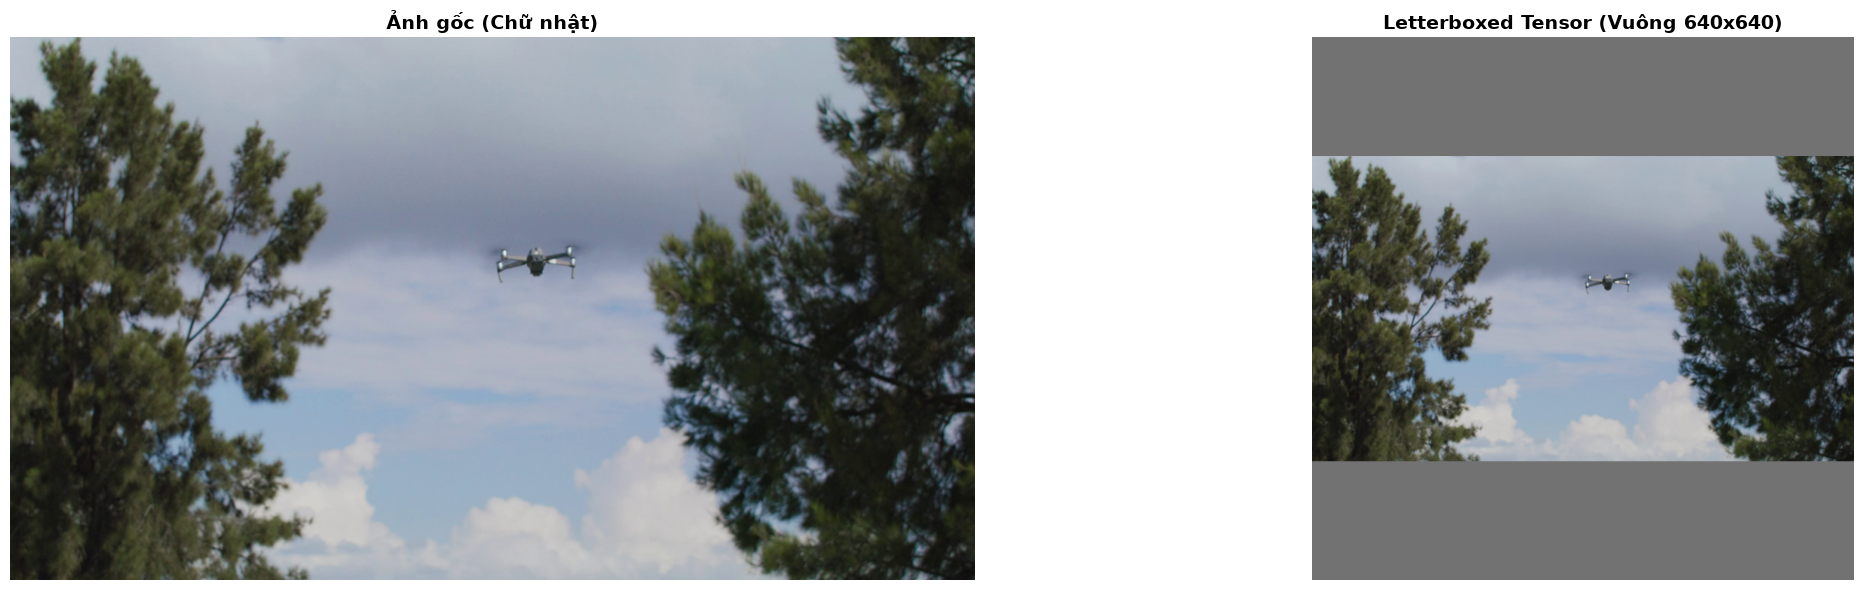

In [2]:
# Kích thước ma trận chuẩn của YOLO
target_size = 640

# 1. Tính toán tỷ lệ thu nhỏ an toàn
h, w = original_frame.shape[:2]
scale = min(target_size / w, target_size / h)
new_w, new_h = int(w * scale), int(h * scale)

# 2. Resize giữ nguyên tỷ lệ
resized_img = cv2.resize(original_frame, (new_w, new_h))

# 3. Tính toán lượng pixel cần bù đắp (Padding)
top = (target_size - new_h) // 2
bottom = target_size - new_h - top
left = (target_size - new_w) // 2
right = target_size - new_w - left

# 4. Padding bằng ma trận màu xám (114, 114, 114) chuẩn của YOLO
letterbox_frame = cv2.copyMakeBorder(resized_img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))

print(f"Kích thước sau Letterboxing: {letterbox_frame.shape}")
plot_images([original_frame, letterbox_frame], ["Ảnh gốc (Chữ nhật)", "Letterboxed Tensor (Vuông 640x640)"])

## Giai đoạn 2: Tích chập (Convolution) - Khai phá đặc trưng
Bên trong mạng nơ-ron, YOLO sử dụng các ma trận Kernel tự học để trượt qua ảnh. 
Để giải thích với hội đồng, ta sẽ **mô phỏng** lớp tích chập nông (Shallow Layer) của YOLO bằng một Kernel dò biên kinh điển trong xử lý ảnh, kết hợp với hàm kích hoạt phi tuyến (Activation Function) để triệt tiêu nhiễu nền trời.

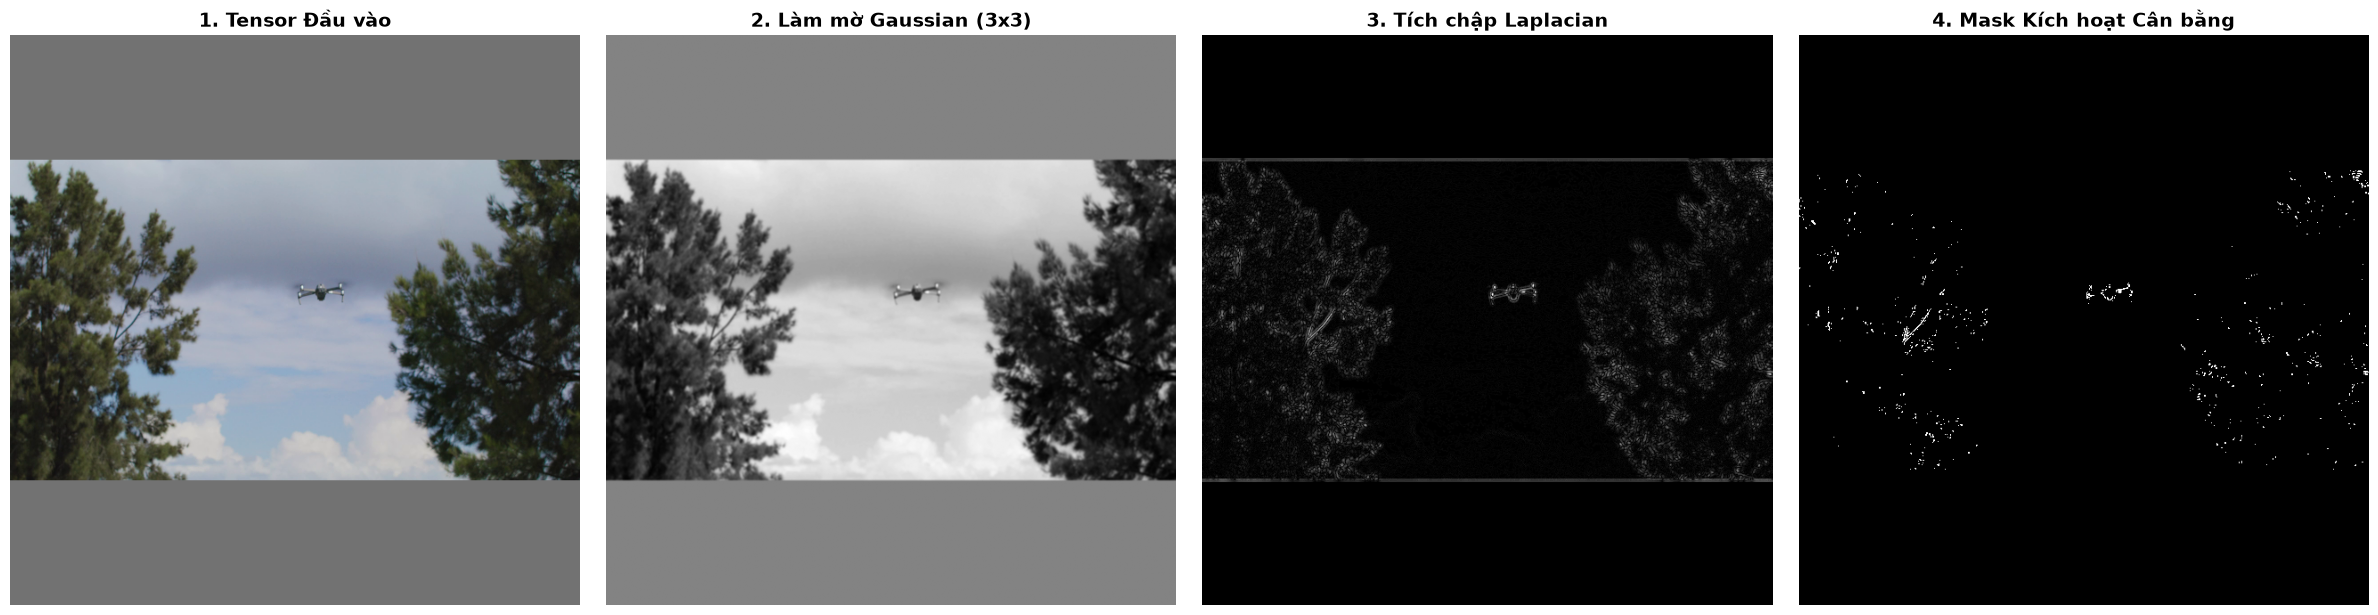

In [5]:
# 1. Chuyển không gian màu sang Grayscale
gray_tensor = cv2.cvtColor(letterbox_frame, cv2.COLOR_BGR2GRAY)

# 2. KHỦ NHIỄU VỪA PHẢI: Đổi kernel Gaussian về (3, 3) để giữ lại nét UAV
blurred_tensor = cv2.GaussianBlur(gray_tensor, (3, 3), 0)

# 3. Phép tích chập Laplacian tìm biên
convoluted_map = cv2.Laplacian(blurred_tensor, cv2.CV_64F)
convoluted_map = cv2.convertScaleAbs(convoluted_map)

# 4. Hạ ngưỡng Threshold xuống 25 (thay vì 50) để không bắt sót UAV
_, activation_map = cv2.threshold(convoluted_map, 25, 255, cv2.THRESH_BINARY)

# 5. Xóa nhiễu ranh giới Letterbox
margin = 12
if top > 0:
    activation_map[top - margin : top + margin, :] = 0
    activation_map[target_size - bottom - margin : target_size - bottom + margin, :] = 0

plot_images(
    [letterbox_frame, blurred_tensor, convoluted_map, activation_map], 
    ["1. Tensor Đầu vào", "2. Làm mờ Gaussian (3x3)", "3. Tích chập Laplacian", "4. Mask Kích hoạt Cân bằng"]
)

## Giai đoạn 3: Hậu xử lý & Kết xuất đồ họa (Post-processing & Rendering)
Từ bản đồ đặc trưng đã được kích hoạt, YOLO xuất ra các vector tọa độ $(x, y, w, h)$.
Sau đó, hệ thống dùng thuật toán toán học NMS (Non-Maximum Suppression) để lọc khung hình, và dùng thư viện xử lý ảnh can thiệp ngược lại vào ma trận pixel gốc để đổi màu hiển thị Bounding Box.

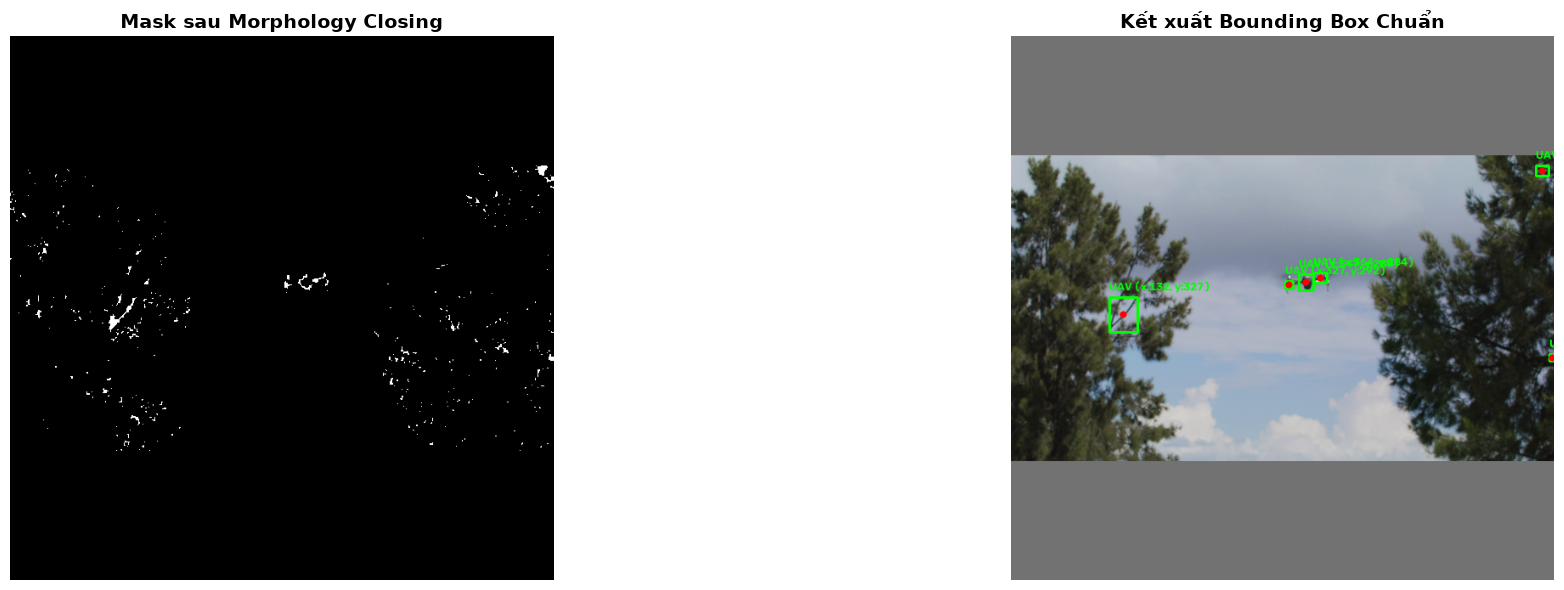

In [6]:
# Phình nhẹ để nối nét UAV
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
closed_map = cv2.morphologyEx(activation_map, cv2.MORPH_CLOSE, kernel_close)

contours, _ = cv2.findContours(closed_map, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

render_frame = letterbox_frame.copy()

for cnt in contours:
    area = cv2.contourArea(cnt)
    
    # Hạ ngưỡng diện tích xuống 20 để bắt được khối UAV vừa gộp
    if 20 < area < 400: 
        x, y, w, h = cv2.boundingRect(cnt)
        aspect_ratio = float(w) / h if h > 0 else 0
        
        if 0.5 < aspect_ratio < 3.0:
            center_x, center_y = x + w // 2, y + h // 2
            
            cv2.rectangle(render_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.circle(render_frame, (center_x, center_y), 4, (0, 0, 255), -1)
            cv2.putText(render_frame, f"UAV (x:{center_x}, y:{center_y})", (x, y - 8), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 2)

plot_images([closed_map, render_frame], ["Mask sau Morphology Closing", "Kết xuất Bounding Box Chuẩn"])